# CSE475 · Task 1 — Image EDA (A–G) · BUSI-WHU Breast Ultrasound Dataset
**Group:** GroupXX  |  **Dataset:** BUSI-WHU (Mendeley Data, DOI 10.17632/k6cpmwybk3.3, CC BY 4.0)  
**Track:** 2 (GCN) / 3 (CNN+Attention) — the EDA is identical for both  
**Problem type:** Binary image classification (benign vs malignant) + tumour segmentation (mask available)

| Part | Content |
|---|---|
| A | Summary table |
| B | Class balance + effect on metrics |
| C | Labelled sample grid (image / mask / overlay) |
| D | Size & resolution |
| E | Pixel & colour statistics |
| F | Image quality (blur, noise, contrast, duplicates) |
| G | Interactive plots (Plotly) |
| + | Mask / tumour analysis, patient-level leakage check, EDA conclusions |



In [8]:
# ---- 0. SETUP -------------------------------------------------------------
# !pip install -q pandas numpy pillow matplotlib seaborn plotly scipy scikit-learn openpyxl scikit-image

import os, re, glob, hashlib, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from PIL import Image
from scipy import ndimage as ndi
from scipy.stats import skew, kurtosis

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# ---- ACTUAL KAGGLE DATASET PATH ------------------------------------------

DATA_DIR = (
    "/kaggle/input/datasets/maharuntanni/"
    "busi-whu-breast-cancer-ultrasound-image-dataset/"
    "BUSI_WHU Breast Cancer Ultrasound Image  Dataset"
)

XLSX_PATH = os.path.join(
    DATA_DIR,
    "Patient_infos_BUSI-WHU.xlsx"
)

OUT_DIR = Path("/kaggle/working/eda_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

# ---- VERIFY PATHS ---------------------------------------------------------

print("DATA_DIR  =", DATA_DIR)
print("Folder exists:", os.path.isdir(DATA_DIR))

print("XLSX_PATH =", XLSX_PATH)
print("Excel exists:", os.path.isfile(XLSX_PATH))

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}"
    )

if not os.path.isfile(XLSX_PATH):
    raise FileNotFoundError(
        f"Patient information Excel file not found: {XLSX_PATH}"
    )

print("\nDataset folder and Excel file verified successfully!")
print("Output directory:", OUT_DIR)

DATA_DIR  = /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset
Folder exists: True
XLSX_PATH = /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/Patient_infos_BUSI-WHU.xlsx
Excel exists: True

Dataset folder and Excel file verified successfully!
Output directory: /kaggle/working/eda_outputs


## 1. Load data — find images, masks and labels

In [18]:
IMG_EXT = ('.png','.jpg','.jpeg','.bmp','.tif','.tiff')
all_files = [p for p in Path(DATA_DIR).rglob('*') if p.suffix.lower() in IMG_EXT]
print('Total image files found:', len(all_files))
print('Example paths:'); [print('  ', p) for p in all_files[:5]]

def is_mask(p):
    s = str(p).lower()
    return bool(re.search(r'(mask|label|gt|ground|annot|seg)', s.replace(str(DATA_DIR).lower(),'')))
mask_files = [p for p in all_files if is_mask(p)]
img_files  = [p for p in all_files if not is_mask(p)]
print(f'Images: {len(img_files)} | Masks: {len(mask_files)}')

Total image files found: 1854
Example paths:
   /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/BUSI-WHU/gt/00001_anno.bmp
   /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/BUSI-WHU/gt/00002_anno.bmp
   /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/BUSI-WHU/gt/00003_anno.bmp
   /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/BUSI-WHU/gt/00006_anno.bmp
   /kaggle/input/datasets/maharuntanni/busi-whu-breast-cancer-ultrasound-image-dataset/BUSI_WHU Breast Cancer Ultrasound Image  Dataset/BUSI-WHU/gt/00007_anno.bmp
Images: 927 | Masks: 927


In [25]:
# --- match each image to its mask (same stem after removing 'mask'/'label' words)
def key(p):
    s = p.stem.lower()
    s = re.sub(r'[_\-\s]*(mask|label|gt|seg|annotation)[_\-\s]*', '', s)
    return s
mask_by_key = {}
for m in mask_files: mask_by_key.setdefault(key(m), m)
df = pd.DataFrame({'image_path': [str(p) for p in img_files]})
df['stem'] = [Path(p).stem for p in df.image_path]
df['mask_path'] = [str(mask_by_key.get(key(Path(p)), '')) for p in df.image_path]
df['has_mask'] = df.mask_path != ''
print('Images with a matched mask:', df.has_mask.sum(), '/', len(df))
df.head()

Images with a matched mask: 0 / 927


,image_path,stem,mask_path,has_mask
0,/kaggle/input/datasets/maharuntanni/busi-whu-b...,00001,,False
1,/kaggle/input/datasets/maharuntanni/busi-whu-b...,00002,,False
2,/kaggle/input/datasets/maharuntanni/busi-whu-b...,00003,,False
3,/kaggle/input/datasets/maharuntanni/busi-whu-b...,00006,,False
4,/kaggle/input/datasets/maharuntanni/busi-whu-b...,00007,,False


In [29]:
# --- labels: try (1) folder name, (2) file name, (3) the patient xlsx
def label_from_text(s):
    s = s.lower()
    if 'malig' in s or re.search(r'(^|[^a-z])m($|[^a-z])', s): return 'malignant'
    if 'benign' in s or re.search(r'(^|[^a-z])b($|[^a-z])', s): return 'benign'
    return None
df['label'] = [label_from_text(str(Path(p).parent)) or label_from_text(Path(p).stem) for p in df.image_path]

meta = None
if os.path.isfile(XLSX_PATH):
    meta = pd.read_excel(XLSX_PATH)
    print('Patient xlsx shape:', meta.shape); print(list(meta.columns)); display(meta.head())
else:
    print('Patient xlsx not found -> set XLSX_PATH')

Patient xlsx shape: (927, 13)
['patient_index', 'Benign(0)\nmalignant(1)', 'img_names', 'scale(pixel/cm)', 'scale_category', 'gt_area(pixel2)', 'Image_area(pixel2)', 'gt(cm2)', 'gt/all', 'centroid_x(pixel)', 'centroid_y(pixel)', 'max_diameter(pixel)', 'min_diameter(pixel)']


,patient_index,Benign(0)\nmalignant(1),img_names,scale(pixel/cm),scale_category,gt_area(pixel2),Image_area(pixel2),gt(cm2),gt/all,centroid_x(pixel),centroid_y(pixel),max_diameter(pixel),min_diameter(pixel)
0,1,0,00001.bmp,101,120-160,67278,179894,6.60,0.37,192,148,322,263
1,2,1,00002.bmp,101,120-160,2056,179894,0.20,0.01,199,101,53,43
2,3,0,00003.bmp,85,80-120,12020,151550,1.66,0.08,307,86,161,94
3,6,1,00006.bmp,119,160-200,13894,275745,0.98,0.05,299,146,246,97
4,7,0,00007.bmp,101,120-160,9772,176314,0.96,0.06,322,89,151,90


In [32]:
# --- merge xlsx info if possible (edit the 2 column names below after looking at the printout above)
ID_COL    = None   # e.g. 'Image' / 'ID' / 'filename' in the xlsx (column that matches image names)
LABEL_COL = None   # e.g. 'Diagnosis' / 'Class' / 'Label' / 'Pathology'
PATIENT_COL = None # e.g. 'Patient ID'
if meta is not None:
    cl = {c.lower(): c for c in meta.columns}
    ID_COL    = ID_COL    or next((cl[k] for k in cl if any(w in k for w in ['image','file','name','id'])), None)
    LABEL_COL = LABEL_COL or next((cl[k] for k in cl if any(w in k for w in ['diagn','class','label','patholog','benign','malig','type'])), None)
    PATIENT_COL = PATIENT_COL or next((cl[k] for k in cl if 'patient' in k), None)
    print('Using ID_COL =', ID_COL, '| LABEL_COL =', LABEL_COL, '| PATIENT_COL =', PATIENT_COL)
    if ID_COL is not None:
        meta['_stem'] = meta[ID_COL].astype(str).str.replace(r'\.\w+$','',regex=True).str.lower()
        df['_stem'] = df.stem.str.lower()
        df = df.merge(meta, on='_stem', how='left')
        if LABEL_COL is not None:
            lab = df[LABEL_COL].astype(str).str.lower()
            df['label'] = np.where(lab.str.contains('malig|^1$|^m$'), 'malignant',
                          np.where(lab.str.contains('benign|^0$|^b$'), 'benign', df['label']))
print('Label counts:'); print(df.label.value_counts(dropna=False))

Using ID_COL = img_names | LABEL_COL = Benign(0)
malignant(1) | PATIENT_COL = patient_index
Label counts:
label
benign       560
malignant    367
Name: count, dtype: int64


## A. Summary table

In [37]:
def load_gray(p): return np.array(Image.open(p).convert('L'))

# Remove duplicate columns if this cell is re-run
df = df.loc[:, ~df.columns.duplicated()].copy()

# Ensure masks are matched before building summary
def fix_key(p):
    s = Path(p).stem.lower()
    return re.sub(r'[_\-\s]*(mask|label|gt|seg|annotation|anno)[_\-\s]*', '', s)
mask_by_key = {fix_key(m): m for m in mask_files}
df['mask_path'] = [str(mask_by_key.get(fix_key(p), '')) for p in df.image_path]
df['has_mask'] = df.mask_path != ''

# Only compute image properties if not already in df
if 'width' not in df.columns:
    rows = []
    for p in df.image_path:
        im = Image.open(p)
        rows.append(dict(width=im.size[0], height=im.size[1], mode=im.mode, fmt=im.format,
                         file_kb=os.path.getsize(p)/1024))
    df = pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

age_cols = [c for c in df.columns if re.search(r'(^|[^a-z])age($|[^a-z])', c.lower())]

summary = pd.DataFrame({
 'Item': ['Name','Source','Area','Problem type','Total images','Classes','Class counts','Masks available',
          'Image formats','Colour modes','Unique resolutions','Mean file size (KB)','Patients (if xlsx)','Age range (if xlsx)'],
 'Value': ['BUSI-WHU','Renmin Hospital of Wuhan University (Mendeley Data, v3, CC BY 4.0)','Medical imaging - breast ultrasound',
           'Binary classification (benign/malignant) + segmentation', len(df), df.label.nunique(),
           df.label.value_counts().to_dict(), int(df.has_mask.sum()),
           ', '.join(df['fmt'].dropna().unique()), ', '.join(df['mode'].unique()),
           df[['width','height']].drop_duplicates().shape[0], round(df['file_kb'].mean(),1),
           df[PATIENT_COL].nunique() if PATIENT_COL in df else 'n/a',
           f"{df[age_cols[0]].min()}-{df[age_cols[0]].max()}" if age_cols else 'n/a']})

display(summary); summary.to_csv(OUT_DIR/'A_summary.csv', index=False)

,Item,Value
0,Name,BUSI-WHU
1,Source,Renmin Hospital of Wuhan University (Mendeley ...
2,Area,Medical imaging - breast ultrasound
3,Problem type,Binary classification (benign/malignant) + seg...
4,Total images,927
5,Classes,2
6,Class counts,"{'benign': 560, 'malignant': 367}"
7,Masks available,927
8,Image formats,BMP
9,Colour modes,L


## B. Class balance

label
benign       560
malignant    367
Majority-to-minority ratio = 1.53


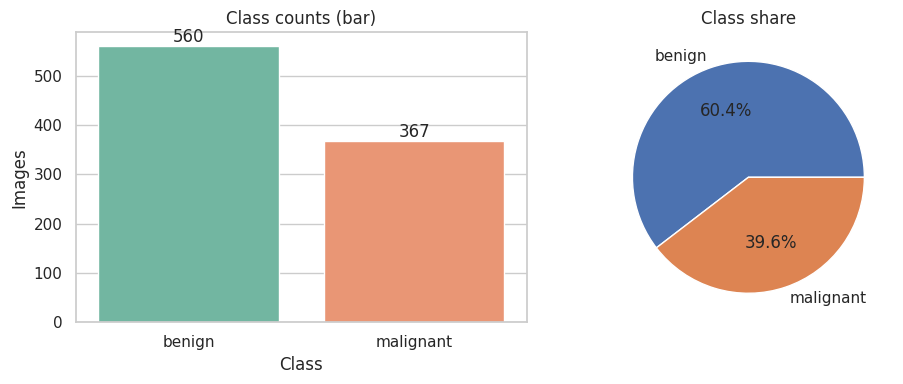

DRAFT reading (verify against your real plots): the dataset is moderately imbalanced (benign is the larger class). Plain accuracy would be optimistic,
so Task 2/3 must report macro-F1, per-class recall, ROC-AUC and PR-AUC, and use stratified splits / class weights.


In [39]:
counts = df.label.fillna('unknown').value_counts()
ratio = counts.max()/max(counts.min(),1)
print(counts.to_string()); print(f'Majority-to-minority ratio = {ratio:.2f}')
fig, ax = plt.subplots(1,2, figsize=(10,4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], palette='Set2'); ax[0].set_title('Class counts (bar)')
ax[0].set_xlabel('Class'); ax[0].set_ylabel('Images')
for i,v in enumerate(counts.values): ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%'); ax[1].set_title('Class share')
plt.tight_layout(); plt.savefig(OUT_DIR/'B_class_balance.png', dpi=150); plt.show()
print('''DRAFT reading (verify against your real plots): the dataset is moderately imbalanced (benign is the larger class). Plain accuracy would be optimistic,
so Task 2/3 must report macro-F1, per-class recall, ROC-AUC and PR-AUC, and use stratified splits / class weights.''')

## C. Labelled sample grid (image · mask · overlay)

Fixed! Images with a matched mask: 927 / 927


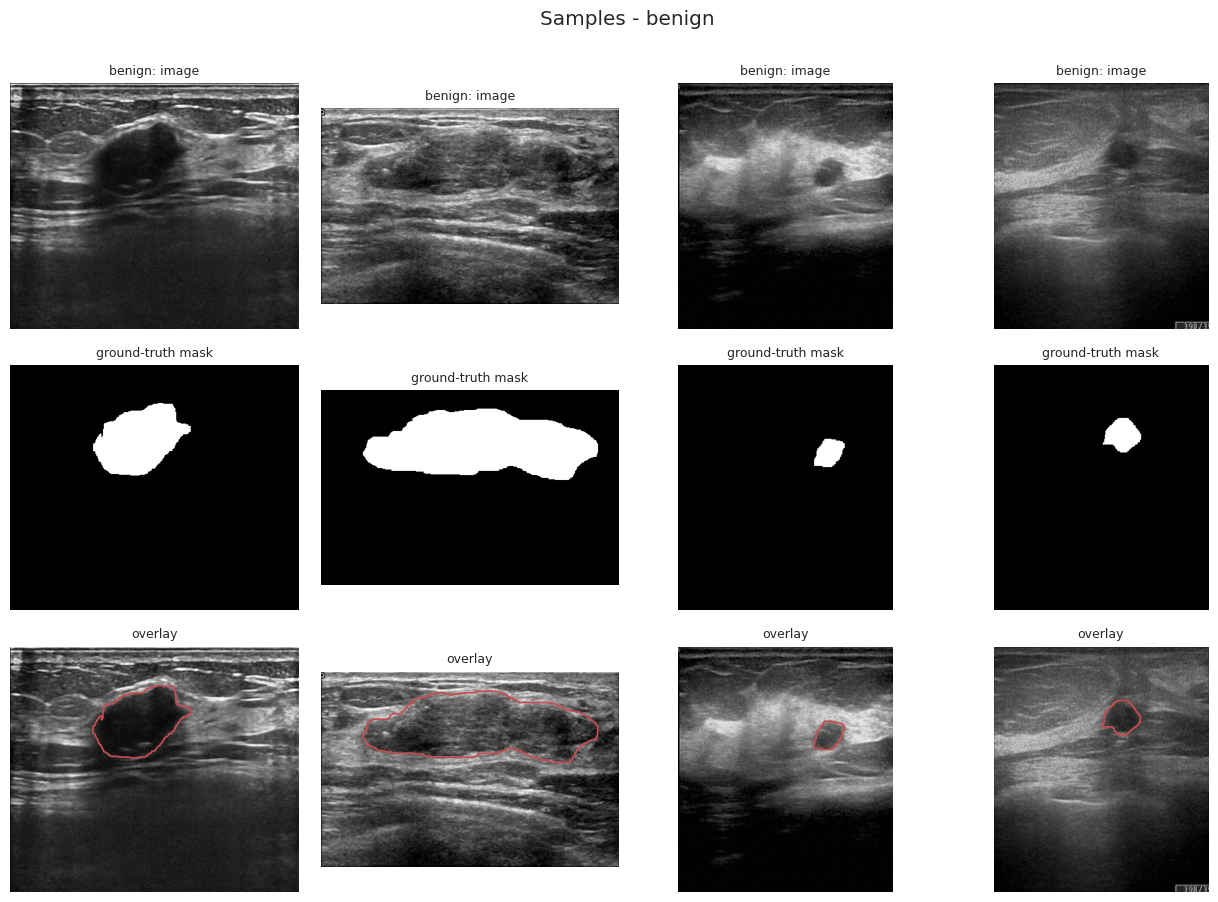

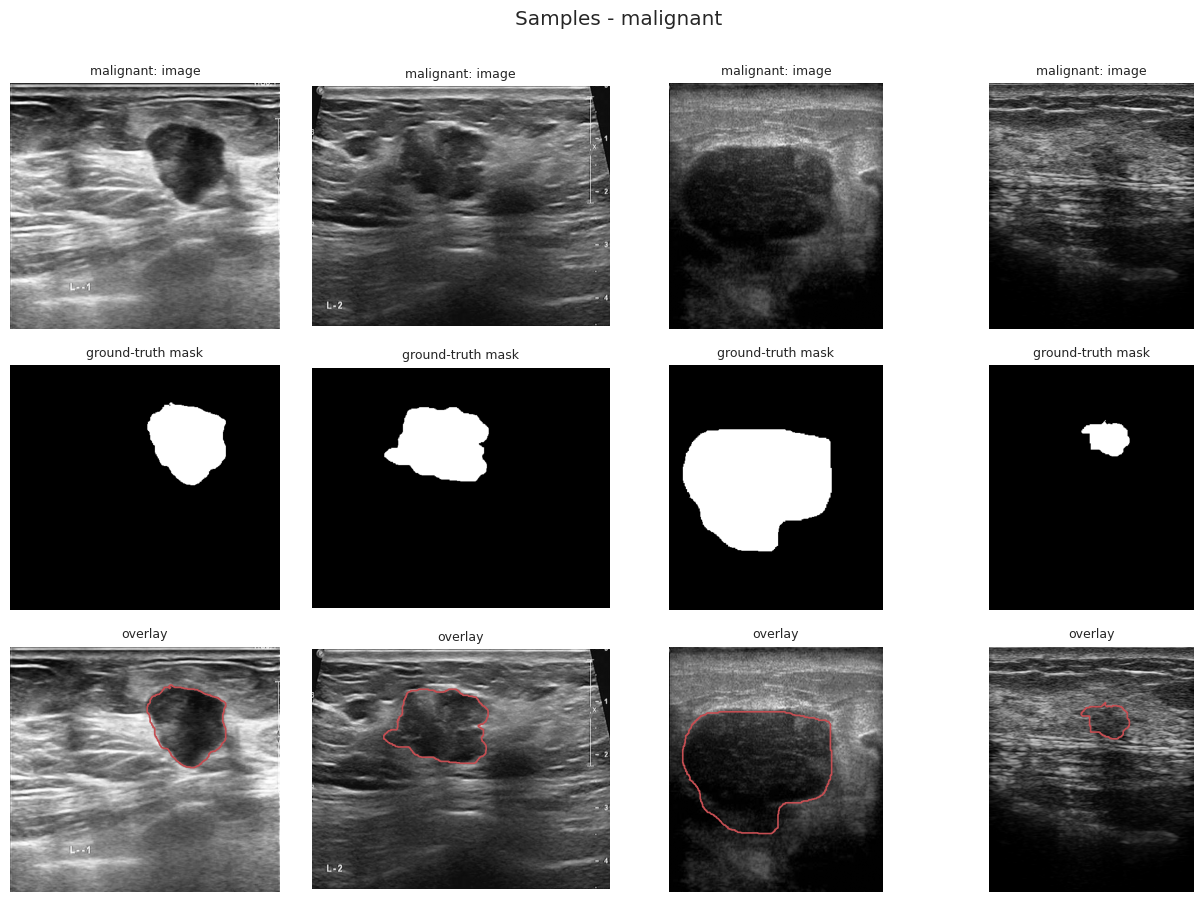

DRAFT reading (verify against your real plots): both classes show speckle noise and low contrast. Benign lesions tend to have smoother, more regular
borders; malignant ones tend to be irregular/spiculated with fuzzy boundaries, so some benign/malignant pairs look alike.


In [40]:
# --- Fix mask matching for '_anno' files so df.has_mask updates properly ---
def fix_key(p):
    s = Path(p).stem.lower()
    return re.sub(r'[_\-\s]*(mask|label|gt|seg|annotation|anno)[_\-\s]*', '', s)

mask_by_key = {fix_key(m): m for m in mask_files}
df['mask_path'] = [str(mask_by_key.get(fix_key(p), '')) for p in df.image_path]
df['has_mask'] = df.mask_path != ''
print('Fixed! Images with a matched mask:', df.has_mask.sum(), '/', len(df))

# --- Cell C: Labelled sample grid (image · mask · overlay) ---
def show_grid(label, n=4):
    sub = df[(df.label==label) & df.has_mask].sample(min(n, ((df.label==label)&df.has_mask).sum()), random_state=SEED)
    fig, ax = plt.subplots(3, len(sub), figsize=(3.2*len(sub), 9), squeeze=False)
    for j,(_,r) in enumerate(sub.iterrows()):
        im = load_gray(r.image_path); mk = load_gray(r.mask_path)
        mk = np.array(Image.fromarray(mk).resize(im.shape[::-1], Image.NEAREST)) > 127
        ax[0,j].imshow(im, cmap='gray'); ax[0,j].set_title(f'{label}: image', fontsize=9)
        ax[1,j].imshow(mk, cmap='gray'); ax[1,j].set_title('ground-truth mask', fontsize=9)
        ax[2,j].imshow(im, cmap='gray'); ax[2,j].contour(mk, colors='r', linewidths=1.2); ax[2,j].set_title('overlay', fontsize=9)
        for a in ax[:,j]: a.axis('off')
    plt.suptitle(f'Samples - {label}', y=1.0); plt.tight_layout()
    plt.savefig(OUT_DIR/f'C_samples_{label}.png', dpi=150); plt.show()

for lab in [l for l in df.label.dropna().unique()]: 
    show_grid(lab)

print('''DRAFT reading (verify against your real plots): both classes show speckle noise and low contrast. Benign lesions tend to have smoother, more regular
borders; malignant ones tend to be irregular/spiculated with fuzzy boundaries, so some benign/malignant pairs look alike.''')

## D. Size / resolution

         width   height  aspect  file_kb
count   927.00   927.00  927.00   927.00
mean    459.86   394.68    1.19   188.88
std     139.53   106.51    0.27   195.66
min     243.00   233.00    0.68    69.20
25%     364.50   316.00    0.88   135.22
50%     433.00   401.00    1.18   153.42
75%     507.00   434.00    1.40   193.08
max    2400.00  1947.00    2.20  4564.33

Top resolutions:
width  height
433    298       11
354    410        9
357    408        8
354    407        6
396    479        5
355    407        5
       408        5
433    297        5
352    410        5
356    410        5
dtype: int64


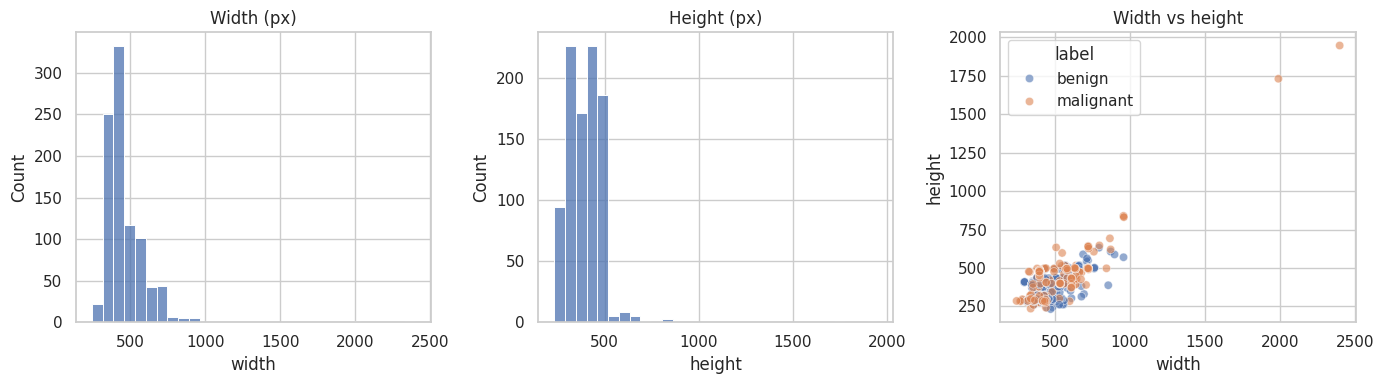

DRAFT reading (verify against your real plots): if sizes vary, all images must be resized to one fixed size (e.g. 224x224 / 256x256) for CNN/GCN; keep aspect ratio via padding to avoid distorting tumours.


In [43]:
df['aspect'] = df.width/df.height
print(df[['width','height','aspect','file_kb']].describe().round(2))
print('\nTop resolutions:'); print(df.groupby(['width','height']).size().sort_values(ascending=False).head(10))
fig, ax = plt.subplots(1,3, figsize=(14,4))
sns.histplot(df.width, bins=30, ax=ax[0]); ax[0].set_title('Width (px)')
sns.histplot(df.height, bins=30, ax=ax[1]); ax[1].set_title('Height (px)')
sns.scatterplot(data=df, x='width', y='height', hue='label', ax=ax[2], alpha=.6); ax[2].set_title('Width vs height')
plt.tight_layout(); plt.savefig(OUT_DIR/'D_size.png', dpi=150); plt.show()
print('DRAFT reading (verify against your real plots): if sizes vary, all images must be resized to one fixed size (e.g. 224x224 / 256x256) for CNN/GCN; keep aspect ratio via padding to avoid distorting tumours.')

## E. Pixel / colour statistics

         mean     std     min     max    skew    kurt       R       G       B
count  927.00  927.00  927.00  927.00  927.00  927.00  927.00  927.00  927.00
mean    77.00   43.51    5.20  236.79    0.69    0.16   77.00   77.00   77.00
std     30.68   12.03   11.27   34.73    0.35    0.87   30.68   30.68   30.68
min     15.55   18.91    0.00  110.00   -0.49   -1.38   15.55   15.55   15.55
25%     51.43   33.45    0.00  237.00    0.46   -0.44   51.43   51.43   51.43
50%     78.53   43.08    0.00  255.00    0.69    0.01   78.53   78.53   78.53
75%     96.99   51.78    2.00  255.00    0.91    0.59   96.99   96.99   96.99
max    168.72   79.84   55.00  255.00    2.31    7.28  168.72  168.72  168.72
Grayscale-looking images: 927 / 927


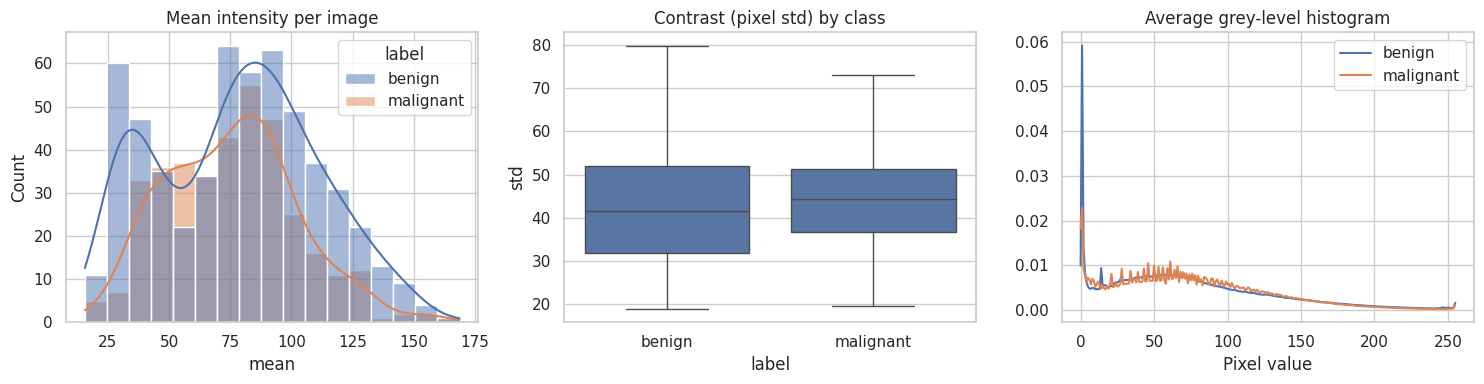

DRAFT reading (verify against your real plots): ultrasound is essentially single-channel; pixel statistics are used to choose normalisation (mean/std). Brightness varies between scans, so normalisation / contrast augmentation helps.


In [44]:
def pix_stats(p):
    im = Image.open(p)
    rgb = np.array(im.convert('RGB')).astype(np.float32)
    g = rgb.mean(2)
    is_gray = bool(np.abs(rgb[...,0]-rgb[...,1]).mean() < 1 and np.abs(rgb[...,1]-rgb[...,2]).mean() < 1)
    return dict(mean=g.mean(), std=g.std(), min=g.min(), max=g.max(), skew=skew(g.ravel()), kurt=kurtosis(g.ravel()),
                R=rgb[...,0].mean(), G=rgb[...,1].mean(), B=rgb[...,2].mean(), looks_grayscale=is_gray)
ps = pd.DataFrame([pix_stats(p) for p in df.image_path]); df = pd.concat([df, ps], axis=1)
print(ps.describe().round(2)); print('Grayscale-looking images:', int(ps.looks_grayscale.sum()), '/', len(ps))
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.histplot(data=df, x='mean', hue='label', kde=True, ax=ax[0]); ax[0].set_title('Mean intensity per image')
sns.boxplot(data=df, x='label', y='std', ax=ax[1]); ax[1].set_title('Contrast (pixel std) by class')
# mean intensity histogram per class
for lab in df.label.dropna().unique():
    h = np.zeros(256)
    for p in df[df.label==lab].image_path.sample(min(100,(df.label==lab).sum()), random_state=SEED):
        h += np.bincount(load_gray(p).ravel(), minlength=256)
    ax[2].plot(h/h.sum(), label=lab)
ax[2].set_title('Average grey-level histogram'); ax[2].set_xlabel('Pixel value'); ax[2].legend()
plt.tight_layout(); plt.savefig(OUT_DIR/'E_pixels.png', dpi=150); plt.show()
print('DRAFT reading (verify against your real plots): ultrasound is essentially single-channel; pixel statistics are used to choose normalisation (mean/std). Brightness varies between scans, so normalisation / contrast augmentation helps.')

## F. Image quality

       blur_var   noise  contrast  dark_frac  bright_frac
count    927.00  927.00    927.00     927.00       927.00
mean     377.64    1.25     43.51       0.15         0.01
std      397.47    0.92     12.03       0.16         0.02
min       27.08    0.00     18.91       0.00         0.00
25%      155.36    1.48     33.45       0.00         0.00
50%      341.17    1.48     43.08       0.09         0.00
75%      517.01    1.48     51.78       0.28         0.01
max     9569.73   11.86     79.84       0.69         0.14


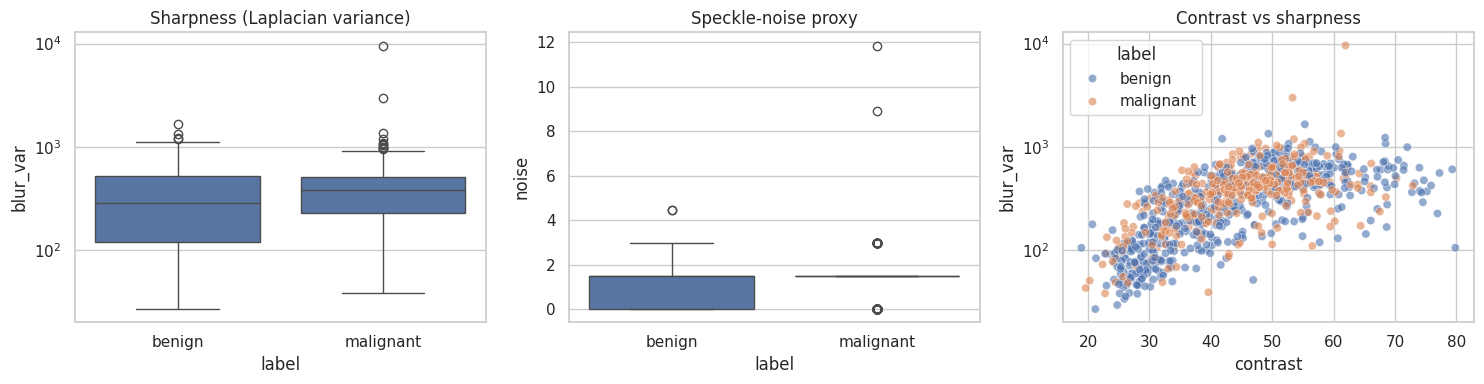

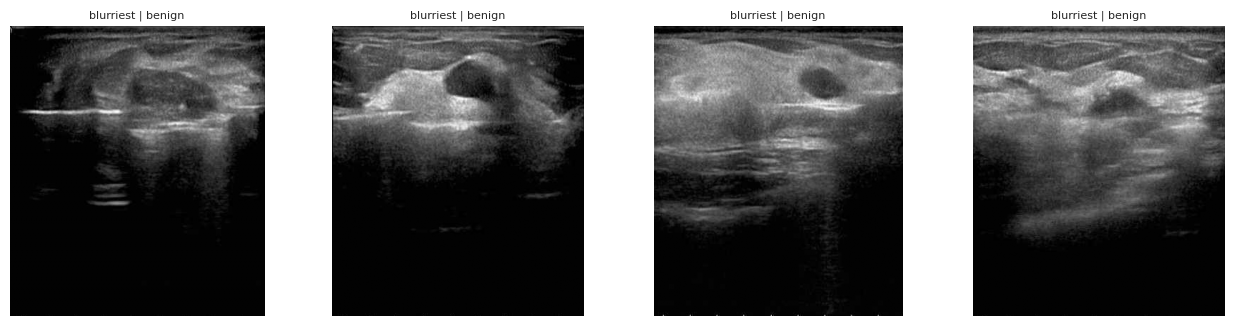

In [45]:
def quality(p):
    g = load_gray(p).astype(np.float32)
    lap = ndi.laplace(g)
    blur = lap.var()                                 # low = blurry
    noise = np.median(np.abs(g - ndi.median_filter(g, 3)))*1.4826   # speckle-noise proxy
    return dict(blur_var=blur, noise=noise, contrast=g.std(),
                dark_frac=(g<20).mean(), bright_frac=(g>235).mean())
q = pd.DataFrame([quality(p) for p in df.image_path]); df = pd.concat([df, q], axis=1)
print(q.describe().round(2))
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.boxplot(data=df, x='label', y='blur_var', ax=ax[0]); ax[0].set_yscale('log'); ax[0].set_title('Sharpness (Laplacian variance)')
sns.boxplot(data=df, x='label', y='noise', ax=ax[1]); ax[1].set_title('Speckle-noise proxy')
sns.scatterplot(data=df, x='contrast', y='blur_var', hue='label', ax=ax[2], alpha=.6); ax[2].set_yscale('log'); ax[2].set_title('Contrast vs sharpness')
plt.tight_layout(); plt.savefig(OUT_DIR/'F_quality.png', dpi=150); plt.show()
blurry = df.nsmallest(4, 'blur_var')
fig, ax = plt.subplots(1,4, figsize=(13,3.4))
for a,(_,r) in zip(ax, blurry.iterrows()): a.imshow(load_gray(r.image_path), cmap='gray'); a.set_title(f'blurriest | {r.label}', fontsize=8); a.axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR/'F_blurriest.png', dpi=150); plt.show()

In [47]:
# duplicates: exact (md5) + near-duplicate (8x8 average hash)  -> duplicates across train/test = leakage
def md5(p): return hashlib.md5(open(p,'rb').read()).hexdigest()
def ahash(p):
    g = np.array(Image.open(p).convert('L').resize((8,8), Image.LANCZOS)).astype(float)
    return ''.join('1' if v else '0' for v in (g > g.mean()).ravel())
df['md5'] = df.image_path.map(md5); df['ahash'] = df.image_path.map(ahash)
exact = df[df.duplicated('md5', keep=False)]; near = df[df.duplicated('ahash', keep=False)]
print('Exact duplicate files:', len(exact), '| near-duplicate (aHash) images:', len(near))
print('Missing masks:', int((~df.has_mask).sum()), '| Unlabelled images:', int(df.label.isna().sum()))
print('Empty masks:', 'checked in the mask section below')
print('''DRAFT reading (verify against your real plots): duplicates / near-duplicates must stay on one side of the split (group them), otherwise scores are inflated.''')

Exact duplicate files: 0 | near-duplicate (aHash) images: 7
Missing masks: 0 | Unlabelled images: 0
Empty masks: checked in the mask section below
DRAFT reading (verify against your real plots): duplicates / near-duplicates must stay on one side of the split (group them), otherwise scores are inflated.


## G. Interactive plots (Plotly)

In [49]:
fig = px.scatter(df, x='mean', y='contrast', color='label', hover_name='stem', title='Brightness vs contrast per image'); fig.show()
fig = px.histogram(df, x='width', color='label', barmode='overlay', title='Image width by class'); fig.show()
fig = px.box(df, x='label', y='blur_var', log_y=True, color='label', points='all', hover_name='stem', title='Sharpness by class'); fig.show()
fig = px.scatter(df, x='width', y='height', color='label', hover_name='stem', title='Resolution map'); fig.show()
print('DRAFT reading (verify against your real plots): hover to find outlier scans (very dark/bright/blurry); the class clouds overlap heavily, so benign vs malignant is not separable by simple intensity statistics -> needs learned features.')

DRAFT reading (verify against your real plots): hover to find outlier scans (very dark/bright/blurry); the class clouds overlap heavily, so benign vs malignant is not separable by simple intensity statistics -> needs learned features.


## + Mask / tumour analysis (what makes this dataset useful for graphs & attention)

       tumour_frac  n_regions  solidity   bbox_h   bbox_w       cx       cy
count      927.000    927.000   927.000  927.000  927.000  927.000  927.000
mean         0.067      1.134     0.908   94.386  159.831    0.503    0.310
std          0.067      0.466     0.065   53.467   96.260    0.088    0.095
min          0.005      1.000     0.366   24.000   37.000    0.224    0.102
25%          0.022      1.000     0.886   57.000   94.000    0.440    0.239
50%          0.043      1.000     0.922   81.000  134.000    0.498    0.300
75%          0.080      1.000     0.948  118.000  200.000    0.561    0.371
max          0.377      5.000     0.984  548.000  935.000    0.866    0.691
Empty masks: 0


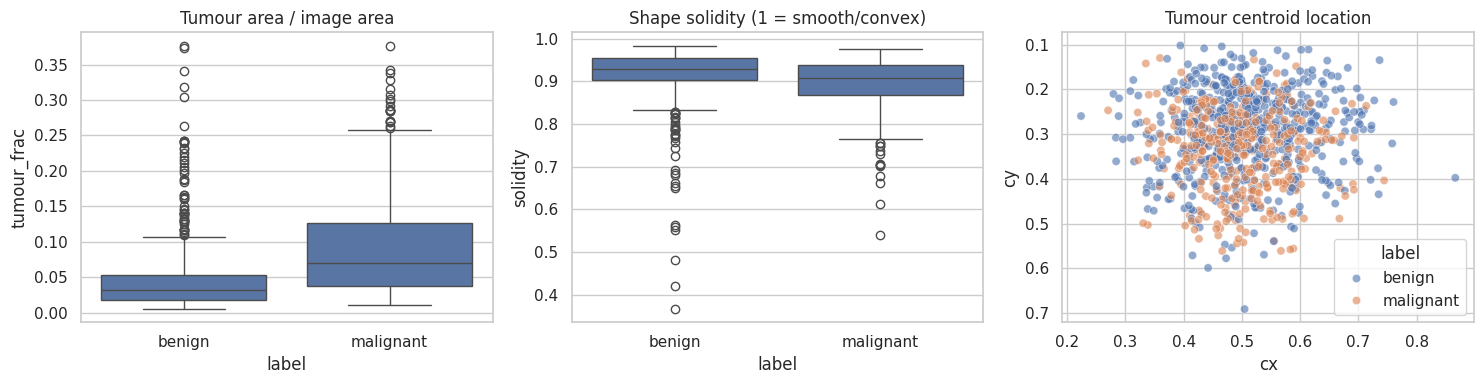

DRAFT reading (verify against your real plots): tumour size and shape differ by class (malignant tends to be less convex), which supports a region/shape graph (Track 2) and an attention model that focuses on the lesion (Track 3).


In [50]:
def mask_stats(r):
    if not r.has_mask: return dict(tumour_frac=np.nan, n_regions=np.nan, solidity=np.nan, bbox_h=np.nan, bbox_w=np.nan, cx=np.nan, cy=np.nan)
    im = load_gray(r.image_path); mk = load_gray(r.mask_path)
    mk = np.array(Image.fromarray(mk).resize(im.shape[::-1], Image.NEAREST)) > 127
    lab, n = ndi.label(mk)
    if mk.sum()==0: return dict(tumour_frac=0, n_regions=0, solidity=np.nan, bbox_h=0, bbox_w=0, cx=np.nan, cy=np.nan)
    ys, xs = np.where(mk)
    try:
        from skimage.measure import regionprops
        sol = max(regionprops(mk.astype(int)), key=lambda x: x.area).solidity
    except Exception: sol = np.nan
    return dict(tumour_frac=mk.mean(), n_regions=n, solidity=sol, bbox_h=ys.max()-ys.min()+1, bbox_w=xs.max()-xs.min()+1,
                cx=xs.mean()/im.shape[1], cy=ys.mean()/im.shape[0])
ms = pd.DataFrame([mask_stats(r) for _, r in df.iterrows()]); df = pd.concat([df, ms], axis=1)
print(ms.describe().round(3)); print('Empty masks:', int((df.tumour_frac==0).sum()))
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.boxplot(data=df, x='label', y='tumour_frac', ax=ax[0]); ax[0].set_title('Tumour area / image area')
sns.boxplot(data=df, x='label', y='solidity', ax=ax[1]); ax[1].set_title('Shape solidity (1 = smooth/convex)')
sns.scatterplot(data=df, x='cx', y='cy', hue='label', ax=ax[2], alpha=.6); ax[2].invert_yaxis(); ax[2].set_title('Tumour centroid location')
plt.tight_layout(); plt.savefig(OUT_DIR/'M_mask_stats.png', dpi=150); plt.show()
print('DRAFT reading (verify against your real plots): tumour size and shape differ by class (malignant tends to be less convex), which supports a region/shape graph (Track 2) and an attention model that focuses on the lesion (Track 3).')

## + Patient-level leakage check (very important, rule 6.2)

In [53]:
if PATIENT_COL and PATIENT_COL in df:
    pc = df.groupby(PATIENT_COL).size()
    print('Patients:', len(pc), '| images per patient: mean', round(pc.mean(),2), 'max', pc.max(), '| patients with >1 image:', int((pc>1).sum()))
    print('Mixed-label patients:', int((df.groupby(PATIENT_COL).label.nunique()>1).sum()))
    print('=> Splits MUST be grouped by patient (GroupKFold / GroupShuffleSplit) so the same patient is never in train and test.')
else:
    print('No patient column detected. The literature reports 927 images from 774 patients, so some patients have several images:')
    print('=> use the patient id from the xlsx with GroupKFold; if it cannot be found, group by duplicate hash and say so in the report.')

Patients: 816 | images per patient: mean 1.14 max 9 | patients with >1 image: 38
Mixed-label patients: 0
=> Splits MUST be grouped by patient (GroupKFold / GroupShuffleSplit) so the same patient is never in train and test.


## + Correlation / redundancy of the numeric image features

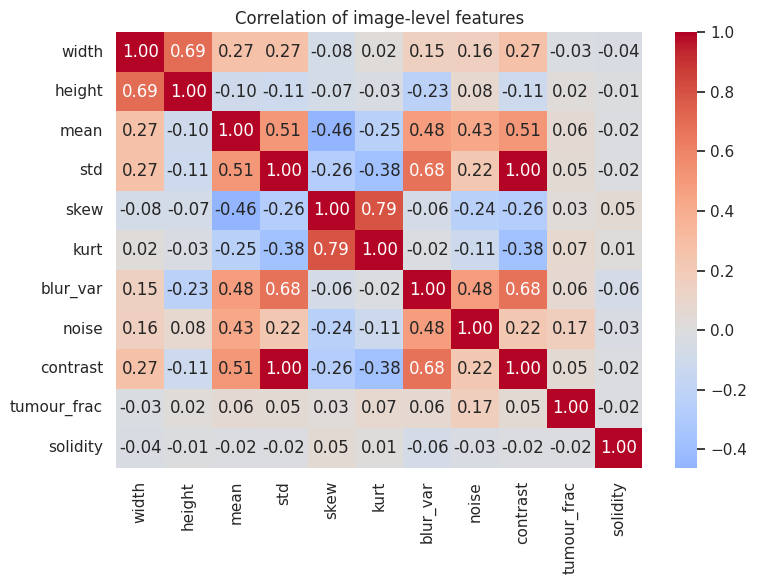

Saved: /kaggle/working/eda_outputs/busi_whu_eda_table.csv


In [55]:
num = df[['width','height','mean','std','skew','kurt','blur_var','noise','contrast','tumour_frac','solidity']].copy()
num['blur_var'] = np.log1p(num.blur_var)
plt.figure(figsize=(8,6)); sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of image-level features'); plt.tight_layout(); plt.savefig(OUT_DIR/'M_corr.png', dpi=150); plt.show()
df.drop(columns=['_stem'], errors='ignore').to_csv(OUT_DIR/'busi_whu_eda_table.csv', index=False)
print('Saved:', OUT_DIR/'busi_whu_eda_table.csv')